**¿Existen grupos de agentes del Mercado Eléctrico Mayorista con patrones de demanda mensual similares (en nivel, estacionalidad y variabilidad), y en qué medida esos grupos coinciden con categorías reales del sistema eléctrico (tipo de agente, región, categoría tarifaria)?**

----------------------------------

**Base original** (CAMMESA, demanda mensual por agente) y limpieza: demanda de texto a número y mes a fecha.

↓

**Tabla intermedia** con agente + mes + demanda.

↓

**Ventana temporal común:** año 2024, con los agentes que demanda positiva (474 agentes).

↓

**Variables por agente** (a partir de feature engineering): nivel de demanda (`log_demanda_media`), variabilidad (`cv`) e índice estacional verano–invierno (`ind_estacional`). Se descartó el factor de carga por su correlación con el cv.

↓

**Revisión de la tabla de agentes:** valores atípicos y agentes con demanda intermitente (se conservan, con justificación), correlaciones y escalado con `RobustScaler`.

↓

**Modelo no supervisado (K-Means):** evaluación de k con el método del codo y la comparación de perfiles, interpretación de los clusters en unidades originales, visualización con PCA y prueba de estabilidad.

↓

**Comparar los integrantes de cada cluster con los tipos de agente reales.**

↓

**Modelo supervisado complementario:** clasificar el tipo de agente con las mismas variables (regresión logística, árbol de decisión y Random Forest, con validación cruzada).

In [94]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import RobustScaler
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, f1_score
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs, make_moons
from sklearn.decomposition import PCA

RANDOM_STATE = 42

**1-BASE DE DATOS ORIGINAL**

In [95]:
##Traemos la base de datos que vamos a usar

df = pd.read_csv('DF - Hoja 1.csv')

In [96]:
df.head(15)

,AÑO,MES,AGENTE NEMO,AGENTE DESCRIPCION,TIPO AGENTE,REGION,PROVINCIA,CATEGORIA AREA,CATEGORIA DEMANDA,CATEGORIA TARIFA,TARIFA,TIPO DEMANDA,DEMANDA [MWh]
0,2022,1/1/2022,AARGTAOY,AEROP ARG 2000 - Aeroparque,GU,GRAN BS.AS.,BUENOS AIRES,Gran Usuario MEM,Gran Usuario,Industrial/Comercial Grande,GUMAS/AUTOGENERADORES,GUMA,"1.537,96"
1,2022,1/1/2022,ABRILHCY,ABRIL CLUB DE CAMPO,GU,GRAN BS.AS.,BUENOS AIRES,Gran Usuario MEM,Gran Usuario,Industrial/Comercial Grande,GUMAS/AUTOGENERADORES,GUMA,"1.676,53"
2,2022,1/1/2022,ACARQQ3Y,ASOC.COOP.ARG. - Quequén,GU,BUENOS AIRES,BUENOS AIRES,Gran Usuario MEM,Gran Usuario,Industrial/Comercial Grande,GUMAS/AUTOGENERADORES,GUMA,"374,89"
3,2022,1/1/2022,ACARSLSY,ASOC.COOP.ARG. - San Lorenzo,GU,LITORAL,SANTA FE,Gran Usuario MEM,Gran Usuario,Industrial/Comercial Grande,GUMAS/AUTOGENERADORES,GUMA,"299,14"
4,2022,1/1/2022,ACERBR1Y,ACERBRAG-Bragado,GU,BUENOS AIRES,BUENOS AIRES,Gran Usuario MEM,Gran Usuario,Industrial/Comercial Grande,GUMAS/AUTOGENERADORES,GUMA,"20.723,27"
5,2022,1/1/2022,ACINTBOY,ACINDAR PTA. TABLADA,GU,GRAN BS.AS.,BUENOS AIRES,Gran Usuario MEM,Gran Usuario,Industrial/Comercial Grande,GUMAS/AUTOGENERADORES,GUMA,"1.624,82"
6,2022,1/1/2022,ACINVCSZ,ACINDAR PTA. V. CONSTITUCION,GU,LITORAL,SANTA FE,Gran Usuario MEM,Gran Usuario,Industrial/Comercial Grande,GUMAS/AUTOGENERADORES,GUMA,"46.166,75"
7,2022,1/1/2022,ACUYLCMY,ACEROS CUYANOS S.A.- L.DE CUYO,GU,CUYO,MENDOZA,Gran Usuario MEM,Gran Usuario,Industrial/Comercial Grande,GUMAS/AUTOGENERADORES,GUMA,"476,74"
8,2022,1/1/2022,AEEZECCY,AEROP ARG 2000 EX FAA EZEIZA,GU,GRAN BS.AS.,BUENOS AIRES,Gran Usuario MEM,Gran Usuario,Industrial/Comercial Grande,GUMAS/AUTOGENERADORES,GUMA,"4.034,09"
9,2022,1/1/2022,AGEABACY,ARTE GRAFICO EDIT. ARG. SA,GU,GRAN BS.AS.,BUENOS AIRES,Gran Usuario MEM,Gran Usuario,Industrial/Comercial Grande,GUMAS/AUTOGENERADORES,GUMA,"934,34"


**2-EDA**

In [97]:
##Dimensiones de la base de datos original

df.shape

(56696, 13)

In [98]:
##Nulos por columna

df.isnull().sum()

AÑO                   0
MES                   0
AGENTE NEMO           0
AGENTE DESCRIPCION    0
TIPO AGENTE           0
REGION                0
PROVINCIA             0
CATEGORIA AREA        0
CATEGORIA DEMANDA     0
CATEGORIA TARIFA      0
TARIFA                0
TIPO DEMANDA          0
DEMANDA [MWh]         0
dtype: int64

In [99]:
##Cantidad de categrorías de variables por columnas

df.nunique()

AÑO                       4
MES                      47
AGENTE NEMO             557
AGENTE DESCRIPCION      547
TIPO AGENTE               5
REGION                    9
PROVINCIA                22
CATEGORIA AREA           11
CATEGORIA DEMANDA         2
CATEGORIA TARIFA          3
TARIFA                   18
TIPO DEMANDA              5
DEMANDA [MWh]         51101
dtype: int64

**DICCIONARIO**

**NEMO** = identificador alfanumérico único que se le asigna a cada agente inscripto en el Mercado Eléctrico Mayorista (MEM) para registrar sus transacciones, consumos o inyecciones de energía.

**DESCRIPCION** = nombre completo del agente.



In [100]:
##TIPO DE AGENTE = clasificación según rol en el mercado.

df['TIPO AGENTE'].unique()

<StringArray>
['GU', 'AG', 'DI', 'AR', 'DM']
Length: 5, dtype: str

In [101]:
##REGION

df['REGION'].unique()

<StringArray>
[ 'GRAN BS.AS.', 'BUENOS AIRES',      'LITORAL',         'CUYO',
      'NORESTE',      'COMAHUE',     'NOROESTE',       'CENTRO',
   'PATAGONICA']
Length: 9, dtype: str

In [102]:
##PROVINCIA

df['PROVINCIA'].unique()

<StringArray>
[  'BUENOS AIRES',       'SANTA FE',        'MENDOZA',       'MISIONES',
       'LA PAMPA',          'SALTA',        'CORDOBA',        'TUCUMAN',
      'CATAMARCA',       'SAN LUIS',          'JUJUY',         'CHUBUT',
        'NEUQUEN',      'RIO NEGRO',     'ENTRE RIOS',       'LA RIOJA',
 'SGO.DEL ESTERO',       'SAN JUAN',     'CORRIENTES',          'CHACO',
     'SANTA CRUZ',        'FORMOSA']
Length: 22, dtype: str

In [103]:
##CATEGORIA AREA = distribuidora/zona.

df['CATEGORIA AREA'].unique()

<StringArray>
['Gran Usuario MEM',            'Resto',       'Entre Rios',
          'Mendoza',           'Edeaba',             'Eden',
           'Edenor',           'Edesur',          'Tucuman',
          'Cordoba',         'Santa Fe']
Length: 11, dtype: str

In [104]:
##CATEGORIA DEMANDA = clasif. según demanda mayorista.

df['CATEGORIA DEMANDA'].unique()

<StringArray>
['Gran Usuario', 'Distribuidor']
Length: 2, dtype: str

In [105]:
##CATEGORIA TARIFA = segmento tarifario.

df['CATEGORIA TARIFA'].unique()

<StringArray>
['Industrial/Comercial Grande', 'Comercial', 'Residencial']
Length: 3, dtype: str

In [106]:
##TARIFA = tarifa específica aplicada.

df['TARIFA'].unique()

<StringArray>
[                        'GUMAS/AUTOGENERADORES',
         'TARIFA USUARIO NO RESIDENCIAL <300KWH',
        'TARIFA USUARIO NO RESIDENCIAL >=300KWH',
  'TARIFA USUARIO NO RESIDENCIAL >=300KWH S Y E',
                                   'RESIDENCIAL',
 'TARIFA BASE ELECTRODEPEND Y BOMBEROS VOLUNTAR',
                                   'GUMES/GUPAS',
                           'RESIDENCIAL NIVEL 1',
                           'RESIDENCIAL NIVEL 2',
                      'RESIDENCIAL NIVEL 3 BASE',
                 'RESIDENCIAL NIVEL 3 EXCEDENTE',
        'CLUBES DE BARRIO Y PRODUCCION AGRICOLA',
 'TARIFA USU.NO RES. HASTA 10 KW Y > 800KWH/MES',
  'TARIFA USU.NO RES. HASTA 10KW Y <=800KWH/MES',
    'TARIFA USUARIO NO RES.>10 KW Y < DE 300 KW',
                             'Alumbrado Publico',
                      'RESIDENCIAL NIVEL 2 BASE',
                 'RESIDENCIAL NIVEL 2 EXCEDENTE']
Length: 18, dtype: str

In [107]:
##TIPO DEMANDA = clasif. según demanda mayorista.

df['TIPO DEMANDA'].unique()

<StringArray>
[                            'GUMA', 'No Residencial (ESTACIONALIZADA)',
                             'GUDI',    'Residencial (ESTACIONALIZADA)',
                             'GUME']
Length: 5, dtype: str

**Tipos de datos**

In [108]:
df.dtypes

AÑO                   int64
MES                     str
AGENTE NEMO             str
AGENTE DESCRIPCION      str
TIPO AGENTE             str
REGION                  str
PROVINCIA               str
CATEGORIA AREA          str
CATEGORIA DEMANDA       str
CATEGORIA TARIFA        str
TARIFA                  str
TIPO DEMANDA            str
DEMANDA [MWh]           str
dtype: object

In [109]:
df['DEMANDA [MWh]'].head(10)

0       1.537,96 
1       1.676,53 
2         374,89 
3         299,14 
4      20.723,27 
5       1.624,82 
6      46.166,75 
7         476,74 
8       4.034,09 
9         934,34 
Name: DEMANDA [MWh], dtype: str

In [110]:
##Transformación de Demanda a float, inicialmnete tiró error porque había valores "-" esos se transforman en 0, ya que se cosidera que es mes no hubo demanda (si no existiera el dato, la fila no debería estar, ya que s una base de datos de demanda mensual)

if not pd.api.types.is_numeric_dtype(df['DEMANDA [MWh]']):
    df['DEMANDA [MWh]'] = (
        df['DEMANDA [MWh]']
        .astype(str)
        .str.strip()
        .str.replace('.', '', regex=False)
        .str.replace(',', '.', regex=False)
    )
    df['DEMANDA [MWh]'] = pd.to_numeric(df['DEMANDA [MWh]'], errors='coerce').fillna(0)
    df['DEMANDA [MWh]'] = df['DEMANDA [MWh]'].astype('float64')

print(df['DEMANDA [MWh]'].dtype)
print("Nulos: ", df['DEMANDA [MWh]'].isnull().sum())
df['DEMANDA [MWh]'].head(10)


float64
Nulos:  0


0     1537.96
1     1676.53
2      374.89
3      299.14
4    20723.27
5     1624.82
6    46166.75
7      476.74
8     4034.09
9      934.34
Name: DEMANDA [MWh], dtype: float64

In [111]:
Porcentaje_Nulos = 100*(df['DEMANDA [MWh]'].isnull().sum())/len(df['DEMANDA [MWh]'])
print(Porcentaje_Nulos,"%")

## estos nulos se van a eliminar de la tabla intermedia

0.0 %


In [112]:
##Transformación de MES a formato fecha

df['MES'] = pd.to_datetime(df['MES'], format='%d/%m/%Y')
df['MES'].unique()

<DatetimeArray>
['2022-01-01 00:00:00', '2022-02-01 00:00:00', '2022-03-01 00:00:00',
 '2022-04-01 00:00:00', '2022-05-01 00:00:00', '2022-06-01 00:00:00',
 '2022-07-01 00:00:00', '2022-08-01 00:00:00', '2022-09-01 00:00:00',
 '2022-10-01 00:00:00', '2022-11-01 00:00:00', '2022-12-01 00:00:00',
 '2023-01-01 00:00:00', '2023-02-01 00:00:00', '2023-03-01 00:00:00',
 '2023-04-01 00:00:00', '2023-05-01 00:00:00', '2023-06-01 00:00:00',
 '2023-07-01 00:00:00', '2023-08-01 00:00:00', '2023-09-01 00:00:00',
 '2023-10-01 00:00:00', '2023-11-01 00:00:00', '2023-12-01 00:00:00',
 '2024-01-01 00:00:00', '2024-02-01 00:00:00', '2024-03-01 00:00:00',
 '2024-04-01 00:00:00', '2024-05-01 00:00:00', '2024-06-01 00:00:00',
 '2024-07-01 00:00:00', '2024-08-01 00:00:00', '2024-09-01 00:00:00',
 '2024-10-01 00:00:00', '2024-11-01 00:00:00', '2024-12-01 00:00:00',
 '2025-01-01 00:00:00', '2025-02-01 00:00:00', '2025-03-01 00:00:00',
 '2025-04-01 00:00:00', '2025-05-01 00:00:00', '2025-06-01 00:00:00',
 '20

**TABLA INTERMEDIA DE AGENTE+MES+DEMANDA [AMD]**

In [113]:
AMD = df.groupby(['AGENTE NEMO', 'MES'], as_index= False)['DEMANDA [MWh]'].sum()
display(AMD)

,AGENTE NEMO,MES,DEMANDA [MWh]
0,AARGTAOY,2022-01-01,1537.96
1,AARGTAOY,2022-02-01,1201.69
2,AARGTAOY,2022-03-01,1246.53
3,AARGTAOY,2022-04-01,1098.70
4,AARGTAOY,2022-05-01,1186.89
...,...,...,...
22802,YPFTREUA,2022-06-01,0.00
22803,YPFTREUA,2022-07-01,0.00
22804,YPFTREUA,2022-08-01,0.00
22805,YPFTREUA,2022-09-01,0.00


In [114]:
AMD.shape

(22807, 3)

In [115]:
meses_por_agente = AMD.groupby('AGENTE NEMO')['MES'].nunique()
meses_por_agente

AGENTE NEMO
AARGTAOY    47
ABRILHCY    47
ACARQQ3Y    47
ACARSLSY    47
ACERBR1Y    47
            ..
YPFPHUQA    47
YPFPTRZZ    47
YPFSECZY    47
YPFTORUZ    47
YPFTREUA    10
Name: MES, Length: 557, dtype: int64

DEMANDA AGREGADA

La curva muestra la demanda mensual total de todos los agentes del MEM. Permite observar el patrón estacional del sistema y la evolución de la demanda a lo largo del período.

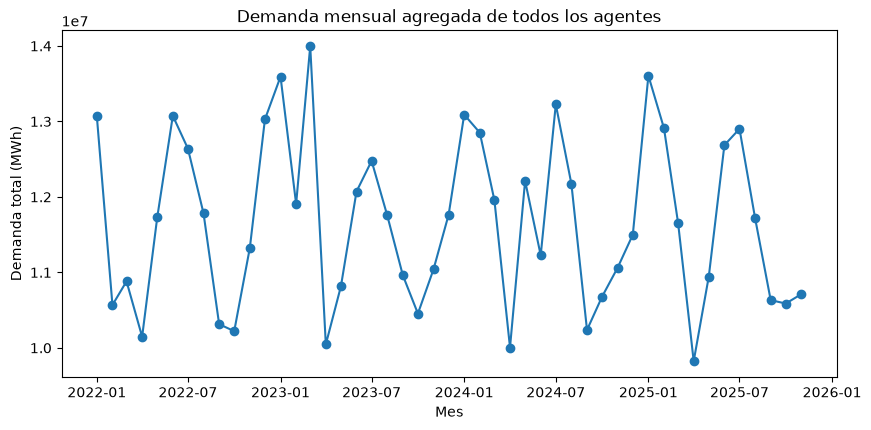

In [116]:
demanda_total = AMD.groupby('MES')['DEMANDA [MWh]'].sum()

plt.figure(figsize=(10, 4.5))
plt.plot(demanda_total.index, demanda_total.values, 'o-')
plt.xlabel('Mes')
plt.ylabel('Demanda total (MWh)')
plt.title('Demanda mensual agregada de todos los agentes')
plt.show()

La demanda agregada del sistema presenta un patrón estacional que se repite todos los años, con dos picos (verano, de diciembre a febrero, e invierno, de junio a agosto) y dos valles (otoño y primavera).Todos los años muestran el mismo ciclo.



**Identificamos posibles ventanas temporales para analizar**

In [117]:
## Identificamos cuántos agentes presentan consumo por año.

def agentes_con_ventana_temporal(inicio, fin):
    ventana = AMD[(AMD['MES'] >= inicio) & (AMD['MES'] <= fin)]

    # Cuántos meses tiene la ventana (12)
    n_meses = len(pd.date_range(inicio, fin, freq='MS'))

    # Agentes que tienen todos los meses de la ventana
    meses = ventana.groupby('AGENTE NEMO')['MES'].nunique()
    con_todos_los_meses = meses[meses == n_meses].index

    # Agentes con demanda promedio mayor a cero dentro de la ventana
    media = ventana.groupby('AGENTE NEMO')['DEMANDA [MWh]'].mean()
    con_demanda = media[media > 0].index

    return con_todos_los_meses.intersection(con_demanda)

print("Año 2022:", len(agentes_con_ventana_temporal('2022-01-01', '2022-12-01')))
print("Año 2023:", len(agentes_con_ventana_temporal('2023-01-01', '2023-12-01')))
print("Año 2024:", len(agentes_con_ventana_temporal('2024-01-01', '2024-12-01')))
print("Dic 2024 a nov 2025:", len(agentes_con_ventana_temporal('2024-12-01', '2025-11-01')))

Año 2022: 454
Año 2023: 468
Año 2024: 474
Dic 2024 a nov 2025: 477


In [118]:
##el año con más datos es el 2024
inicio = '2024-01-01'
fin = '2024-12-01'

agentes_ventana = agentes_con_ventana_temporal(inicio, fin)

AMD_ventana = AMD[
    (AMD['AGENTE NEMO'].isin(agentes_ventana)) &
    (AMD['MES'] >= inicio) &
    (AMD['MES'] <= fin)
].copy()

print(AMD_ventana['AGENTE NEMO'].nunique())
print(AMD_ventana.shape)
print(AMD_ventana.groupby('AGENTE NEMO')['MES'].count().unique())

474
(5688, 3)
[12]


**Calculamos las métricas a partir de las cuales vamos a aplicar los modelos**

In [119]:
## CV = Variablidad, mide cuánto varía la demanda mes a mes, sin depender del tamaño del agente.
## log_demanda_media = Nivel, mide que tan grande es el agente.
## factor_carga = mide qué tan parejo es el consumo de un agente a lo largo del año.


metricas = AMD_ventana.groupby('AGENTE NEMO')['DEMANDA [MWh]'].agg(
    demanda_media='mean',
    desvio='std',
    demanda_max='max',
)

metricas['cv'] = metricas['desvio'] / metricas['demanda_media']
metricas['factor_carga'] = metricas['demanda_media'] / metricas['demanda_max']
metricas['log_demanda_media'] = np.log(metricas['demanda_media'])

print(metricas.shape)
print(metricas.isna().sum())
metricas.head()

(474, 6)
demanda_media        0
desvio               0
demanda_max          0
cv                   0
factor_carga         0
log_demanda_media    0
dtype: int64


,demanda_media,desvio,demanda_max,cv,factor_carga,log_demanda_media
AGENTE NEMO,,,,,,
AARGTAOY,1443.743333,213.290548,1851.39,0.147734,0.779816,7.274995
ABRILHCY,1197.181667,204.110262,1609.52,0.170492,0.743813,7.087725
ACARQQ3Y,406.798333,91.921379,551.61,0.225963,0.737475,6.008318
ACARSLSY,394.411667,60.792268,499.20,0.154134,0.790087,5.977395
ACERBR1Y,18403.587500,5981.133519,24746.36,0.324998,0.743689,9.820301


Como el sistema tiene picos de magnitud similar en verano e invierno, el índice estacional (verano − invierno) / media del conjunto es cercano a 0. En consecuencia, el índice identifica a los agentes que se apartan de ese patrón, con predominio de verano (valores positivos) o de invierno (valores negativos), y no mide la estacionalidad en general.

In [120]:
## Evaluamos la demanda estacional en verano e invierno.

AMD_ventana['mes_num'] = AMD_ventana['MES'].dt.month

verano = AMD_ventana[AMD_ventana['mes_num'].isin([12, 1, 2])]
invierno = AMD_ventana[AMD_ventana['mes_num'].isin([6, 7, 8])]

metricas['media_verano'] = verano.groupby('AGENTE NEMO')['DEMANDA [MWh]'].mean()
metricas['media_invierno'] = invierno.groupby('AGENTE NEMO')['DEMANDA [MWh]'].mean()

metricas['ind_estacional'] = ((metricas['media_verano'] - metricas['media_invierno']) / metricas['demanda_media'])

print(metricas.shape)
print(metricas.isna().sum())
print(metricas['ind_estacional'].describe())

(474, 9)
demanda_media        0
desvio               0
demanda_max          0
cv                   0
factor_carga         0
log_demanda_media    0
media_verano         0
media_invierno       0
ind_estacional       0
dtype: int64
count    474.000000
mean       0.040032
std        0.455930
min       -3.568891
25%       -0.095615
50%        0.027371
75%        0.196126
max        2.057173
Name: ind_estacional, dtype: float64


In [121]:
variables_modelo = ['log_demanda_media', 'cv', 'factor_carga', 'ind_estacional']

print(metricas[variables_modelo].describe())

print("\nAgentes con |índice estacional| > 1:", (metricas['ind_estacional'].abs() > 1).sum())

print("\nLos 5 mayor consumo invierno:")
print(metricas.sort_values('ind_estacional').head(5)[['demanda_media', 'media_verano', 'media_invierno', 'ind_estacional']])

print("\nLos 5 mayor consumo verano:")
print(metricas.sort_values('ind_estacional').tail(5)[['demanda_media', 'media_verano', 'media_invierno', 'ind_estacional']])

       log_demanda_media          cv  factor_carga  ind_estacional
count         474.000000  474.000000    474.000000      474.000000
mean            7.681942    0.270801      0.774658        0.040032
std             1.907926    0.444930      0.169364        0.455930
min            -2.155603    0.016944      0.083333       -3.568891
25%             6.699887    0.098157      0.737506       -0.095615
50%             7.505900    0.143199      0.826813        0.027371
75%             8.496007    0.243963      0.874600        0.196126
max            14.537245    3.464102      0.983157        2.057173

Agentes con |índice estacional| > 1: 19

Los 5 mayor consumo invierno:
             demanda_media  media_verano  media_invierno  ind_estacional
AGENTE NEMO                                                             
YPFLOMQA          9.804167      2.113333       37.103333       -3.568891
YPFLPEZA        964.054167    115.323333     3219.650000       -3.220075
SHELDSCA        139.595833     14

In [122]:
##Identificamos cuántos agentes tienen demanda intermitente (menos de 12 meses al año)
##AG y AR son autogeneradores.

# Evaluamos tipo de agente con demanda itermitente 
tipo = df.drop_duplicates(subset='AGENTE NEMO').set_index('AGENTE NEMO')['TIPO AGENTE']
clase = tipo.map({'GU': 'Gran Usuario', 'DI': 'Distribuidor', 'AG': 'Autogenerador G', 'AR': 'Autogenerador R'})

metricas['meses_con_demanda'] = (
    AMD_ventana[AMD_ventana['DEMANDA [MWh]'] > 0]
    .groupby('AGENTE NEMO')['MES']
    .count()
)

print(metricas['meses_con_demanda'].value_counts().sort_index())

print("\nAgentes con menos de 12 meses con demanda:")
intermitentes = metricas[metricas['meses_con_demanda'] < 12][['demanda_media', 'cv', 'factor_carga', 'meses_con_demanda']].copy()
intermitentes['clase'] = clase[intermitentes.index]
print(intermitentes.sort_values('meses_con_demanda'))

print("\nIntermitentes por tipo de agente:")
print(intermitentes['clase'].value_counts())

meses_con_demanda
1       2
3       1
4       1
5       1
6       1
7       1
8       3
9       3
10      2
11      3
12    456
Name: count, dtype: int64

Agentes con menos de 12 meses con demanda:
             demanda_media        cv  factor_carga  meses_con_demanda  \
AGENTE NEMO                                                             
CGCOHUZA          0.157500  3.464102      0.083333                  1   
CAPEX-QA         16.346667  3.464102      0.083333                  1   
YPFPHUQA         52.535000  2.378759      0.140359                  3   
YPFLOMQA          9.804167  3.048987      0.093838                  4   
LAPLATAA       1052.135000  2.915645      0.097966                  5   
ARCOMSXA        349.935000  2.059707      0.171303                  6   
PAPELMNA        280.767500  2.212602      0.132099                  7   
CGCOMEZA          0.115833  1.111966      0.289583                  8   
YPFTORUZ        639.320833  1.010303      0.467319                  8   

De los 474 agentes, 456 registran demanda positiva en los 12 meses de 2024 y 18 presentan demanda intermitente, con entre 1 y 11 meses con demanda. La intermitencia se concentra en los Autogeneradores: 15 de los 31 agentes de esa clase son intermitentes, frente a 3 de 366 Grandes Usuarios y ningún Distribuidor. Este patrón es coherente con un comportamiento propio del tipo de agente (compras ocasionales a la red, complementarias a su generación propia), por lo que se conservaron todos los agentes intermitentes: eliminarlos implicaría perder casi la mitad de la clase Autogenerador y sesgar el análisis. Se reconoce como limitación que, para estos agentes, las métricas (en particular el coeficiente de variación y el índice estacional) se calculan sobre pocos meses.



**Evaluamos los oultiers de la tabla intermedia**

In [123]:
# 1-Clase de cada agente
tipo = df.drop_duplicates(subset='AGENTE NEMO').set_index('AGENTE NEMO')['TIPO AGENTE']
clase = tipo.map({'GU': 'Gran Usuario', 'DI': 'Distribuidor', 'AG': 'Autogenerador', 'AR': 'Autogenerador'})

# 2-Outliers según IQR
variables = ['log_demanda_media', 'cv', 'ind_estacional']
q1 = metricas[variables].quantile(0.25)
q3 = metricas[variables].quantile(0.75)
iqr = q3 - q1
es_outlier = (metricas[variables] < q1 - 1.5 * iqr) | (metricas[variables] > q3 + 1.5 * iqr)

print(es_outlier.sum())


# 3-Agentes con al menos un outlier, por tipo de agente
alguno = es_outlier.any(axis=1)
print('Con algún outlier:', alguno.sum(), 'de', len(alguno))
print((alguno.groupby(clase[alguno.index]).mean() * 100).round(0))

log_demanda_media    39
cv                   52
ind_estacional       38
dtype: int64
Con algún outlier: 90 de 474
TIPO AGENTE
Autogenerador    81.0
Distribuidor     33.0
Gran Usuario     11.0
dtype: float64


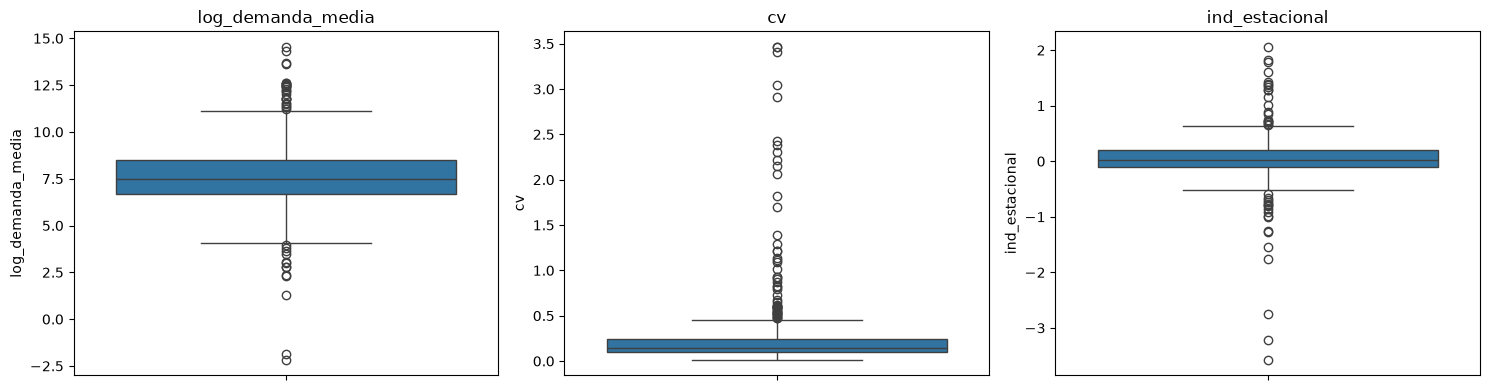

In [124]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))

for eje, v in zip(ejes, variables):
    sns.boxplot(y=metricas[v], ax=eje)
    eje.set_title(v)

plt.tight_layout()
plt.show()

Los valores atípicos no son errores de carga sino agentes reales con perfiles de consumo distintos, y se concentran en los tipos de agente minoritarios: el 81 % de los Autogeneradores y el 33 % de los Distribuidores, frente al 11 % de los Grandes Usuarios. Eliminarlos implicaría perder casi toda la clase Autogenerador y distorsionar la comparación con las categorías reales, por lo que se decidió conservarlos..

In [125]:
## Eliminamos la columna de meses con demanda porque se refleja en CV
 
metricas = metricas.drop(columns=['meses_con_demanda'])
metricas.head()

,demanda_media,desvio,demanda_max,cv,factor_carga,log_demanda_media,media_verano,media_invierno,ind_estacional
AGENTE NEMO,,,,,,,,,
AARGTAOY,1443.743333,213.290548,1851.39,0.147734,0.779816,7.274995,1730.790000,1317.560000,0.286221
ABRILHCY,1197.181667,204.110262,1609.52,0.170492,0.743813,7.087725,1422.970000,1247.876667,0.146255
ACARQQ3Y,406.798333,91.921379,551.61,0.225963,0.737475,6.008318,326.903333,517.983333,-0.469717
ACARSLSY,394.411667,60.792268,499.20,0.154134,0.790087,5.977395,384.343333,382.620000,0.004369
ACERBR1Y,18403.587500,5981.133519,24746.36,0.324998,0.743689,9.820301,18806.510000,22974.100000,-0.226455


Demanda media, desvío, demanda max, media inv, media verano están reflejadas en CV, factor de carga e ind_estacional.



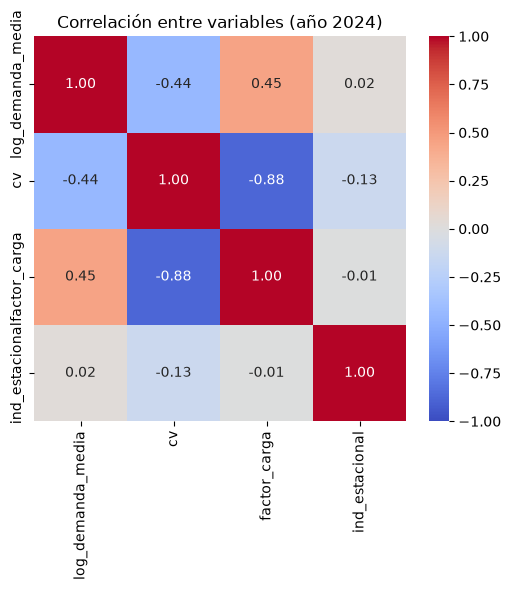

In [126]:
## Heatmap de correlaciones para saber si hay variables que dan la misma info (si la correlación>0,8 dan la misma info)

plt.figure(figsize=(6, 5))
sns.heatmap(
    metricas[variables_modelo].corr(),
    annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1
)
plt.title('Correlación entre variables (año 2024)')
plt.show()

In [127]:
## En el heatmap se ve que CV y factor_carga tienen una correlación alta, así que solo dejamos CV.
## La variables finales son CV, log_demanda_media y el ind_estacional.
## Previo a escalar las variables finales evaluamos si la distribución es normal.

variables_modelo_final = ['log_demanda_media', 'cv', 'ind_estacional']

X = metricas[variables_modelo_final]



**ESCALADO**

log_demanda_media   -0.03
cv                   4.75
ind_estacional      -1.83
dtype: float64


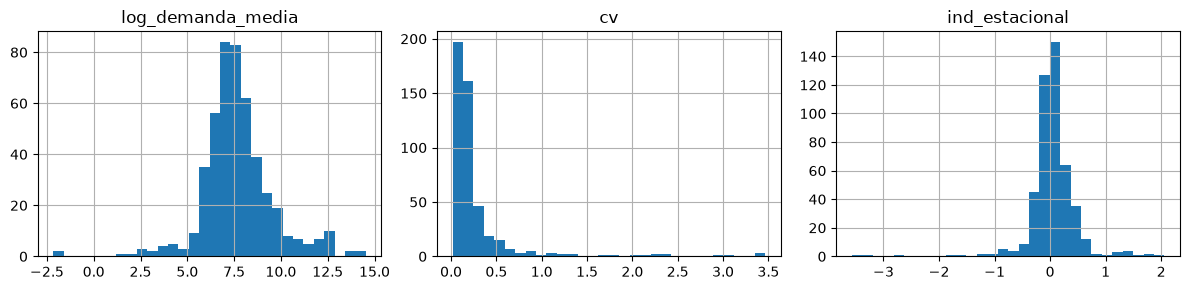

In [128]:
print(metricas[variables_modelo_final].skew().round(2))

metricas[variables_modelo_final].hist(bins=30, figsize=(12, 3), layout=(1, 3))
plt.tight_layout()
plt.show()

In [129]:
## Como CV no tiene distribución normal usamos RobustScaler.

scaler = RobustScaler()
X_esc = pd.DataFrame(
    scaler.fit_transform(X),
    index=X.index,
    columns=variables_modelo_final
)

print(X_esc.shape)
print(X_esc.median().round(2))
print((X_esc.quantile(0.75) - X_esc.quantile(0.25)).round(2))
print(X_esc.agg(['min', 'max']).round(1))

(474, 3)
log_demanda_media    0.0
cv                  -0.0
ind_estacional      -0.0
dtype: float64
log_demanda_media    1.0
cv                   1.0
ind_estacional       1.0
dtype: float64
     log_demanda_media    cv  ind_estacional
min               -5.4  -0.9           -12.3
max                3.9  22.8             7.0


**MODELO DE APRENDIZAJE NO SUPERVISADO**

In [130]:
## Dejamos listo el df para el modelo de aprendizaje no supervisado.

df_nosup = X_esc.copy()

print(df_nosup.shape)
print()
print(df_nosup.isna().sum())
print()
print(df_nosup.index.duplicated().sum())

df_nosup.head(5)

(474, 3)

log_demanda_media    0
cv                   0
ind_estacional       0
dtype: int64

0


,log_demanda_media,cv,ind_estacional
AGENTE NEMO,,,
AARGTAOY,-0.128558,0.031109,0.887259
ABRILHCY,-0.232821,0.187192,0.407495
ACARQQ3Y,-0.833787,0.567633,-1.703867
ACARSLSY,-0.851004,0.075000,-0.078844
ACERBR1Y,1.288556,1.246856,-0.870041


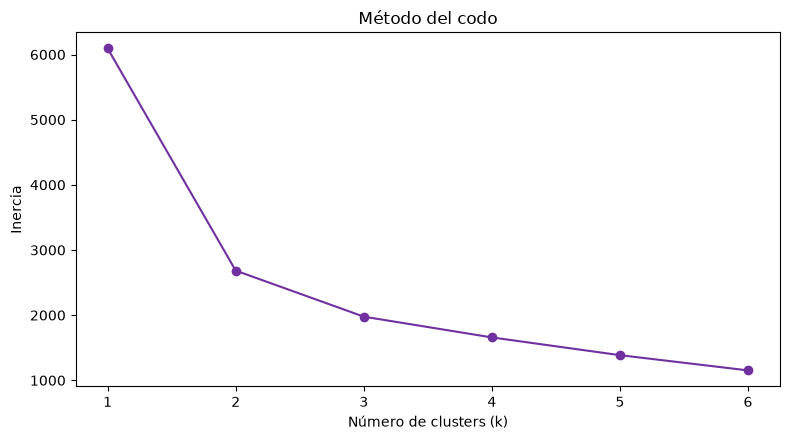

In [131]:
##Como se trata de variables numéricas continuas, vamos a usar KMeans para identificar patrones de consumo de los agentes.

valores_k = range(1, 7)
inercias = [KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(df_nosup).inertia_ for k in valores_k]

plt.figure(figsize=(8, 4.5))
plt.plot(valores_k, inercias, "o-", color="#7030A0")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Inercia")
plt.title("Método del codo")
plt.xticks(list(valores_k))
plt.tight_layout()
plt.show()

El codo se observa en k = 2 y hay un quiebre más suave k =3

Considerando los datos originales, comparamos los perfiles de los clusters con k = 3 y 4

In [132]:
for k in [3, 4]:
    etiquetas = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(df_nosup)
    perfil = metricas.loc[df_nosup.index].assign(cluster=etiquetas).groupby("cluster")[["demanda_media", "cv", "ind_estacional"]].mean().round(2)
    perfil["agentes"] = pd.Series(etiquetas).value_counts().sort_index()
    print(f"k = {k}")
    display(perfil)

k = 3


,demanda_media,cv,ind_estacional,agentes
cluster,,,,
0,26685.31,0.17,0.02,436
1,832.18,0.96,0.66,28
2,263.81,2.78,-0.95,10


k = 4


,demanda_media,cv,ind_estacional,agentes
cluster,,,,
0,27769.00,0.15,0.05,417
1,241.73,2.69,-0.86,11
2,2315.82,0.61,-0.64,25
3,976.44,0.92,1.06,21


**k = 3**

0 = Demanda alta, muy estable, sin estacionalidad. 
1 = Demanda media-baja, variabilidad media, estacionalidad marcada positiva.
2 = Demanda baja, cv alto, estacionalidad negativa.

**k = 4**

0 = Demanda alta, muy estable, sin estacionalidad.
1 = es el cluster 2 de k3 (Demanda baja, cv alto, estacionalidad negativa).
2 = Demanda media-alta, variabilidad media, estacionalidad negativa.
3 = Demanda media-baja, variabilidad media-alta, estacionalidad marcada positiva.

----------------------------

Hay un cluster grande donde los agentes son de demanda alta y estable. 
El paso de k = 3 a k = 4: cluster 1 de k = 3 (estacionalidad +0,66) se desdobla en dos grupos de estacionalidad opuesta, uno positivo (+1,06) y otro negativo (−0,64). En k = 3 esos dos patrones quedan mezclados en un solo promedio.
El cluster con mayor variabilidad (cv 2,7–2,8) no cambia entre k = 3 y k = 4. Es estable y probablemente sean los agentes intermitentes.







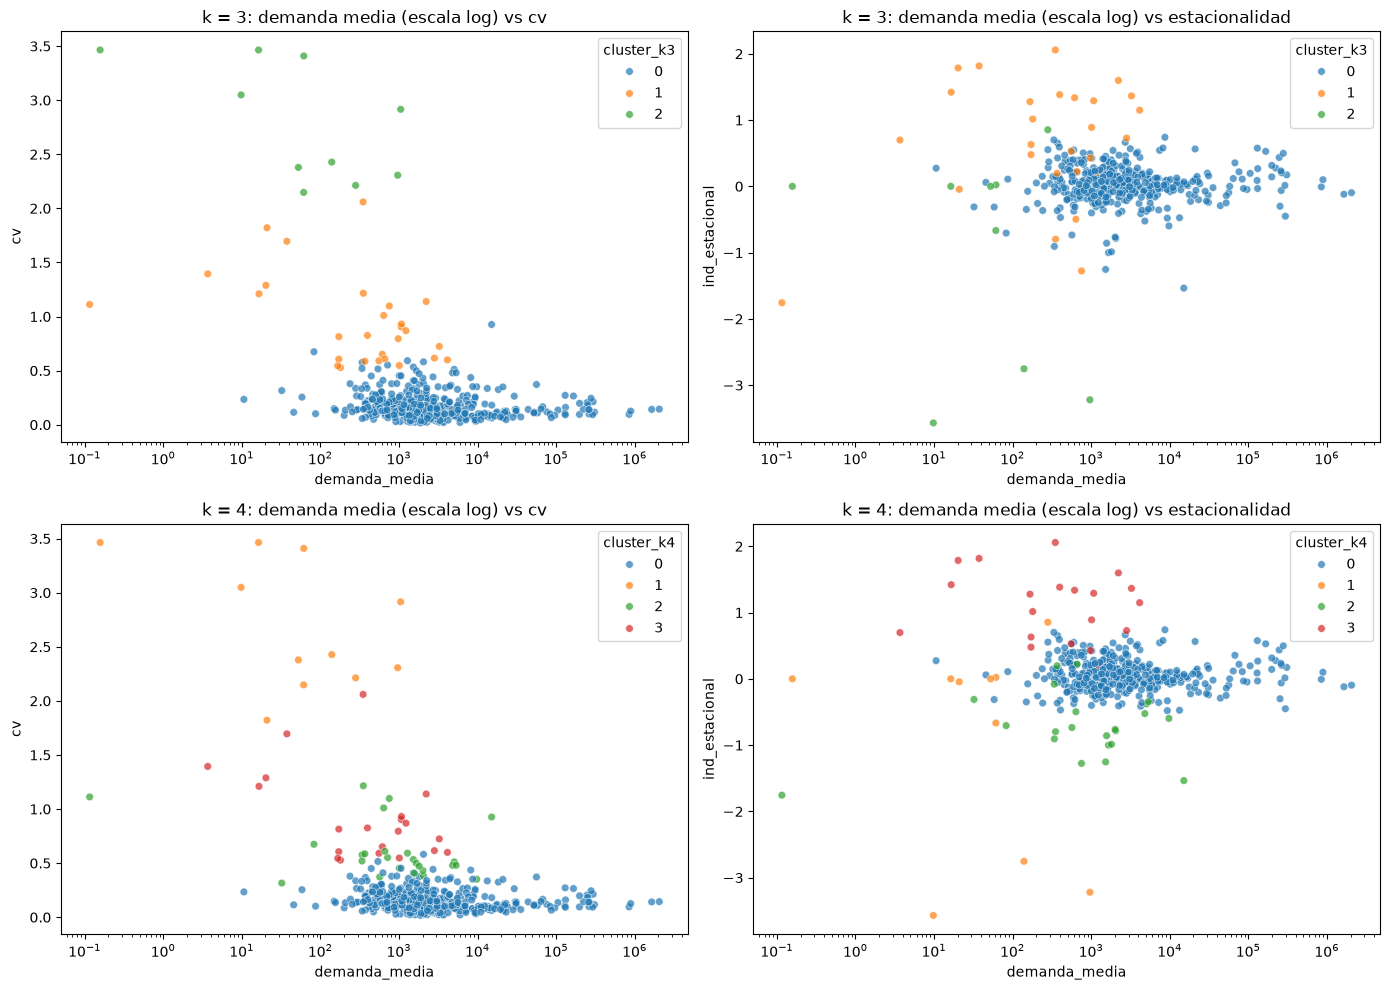

In [133]:
datos = metricas.loc[df_nosup.index].copy()

for k in [3, 4]:
    datos[f"cluster_k{k}"] = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(df_nosup)

fig, ax = plt.subplots(2, 2, figsize=(14, 10))

for fila, k in enumerate([3, 4]):
    sns.scatterplot(data=datos, x="demanda_media", y="cv", hue=f"cluster_k{k}",
                    palette="tab10", alpha=0.7, s=30, ax=ax[fila, 0])
    ax[fila, 0].set_xscale("log")
    ax[fila, 0].set_title(f"k = {k}: demanda media (escala log) vs cv")

    sns.scatterplot(data=datos, x="demanda_media", y="ind_estacional", hue=f"cluster_k{k}",
                    palette="tab10", alpha=0.7, s=30, ax=ax[fila, 1])
    ax[fila, 1].set_xscale("log")
    ax[fila, 1].set_title(f"k = {k}: demanda media (escala log) vs estacionalidad")

plt.tight_layout()
plt.show()

Como el codo no define un único valor, se compararon los perfiles de k = 3 y k = 4. Se eligió k = 4 por interpretabilidad: separa dos grupos de estacionalidad opuesta (pico de verano y pico de invierno) que con k = 3 quedan mezclados en un solo grupo.

**PCA**

Usamos PCA para reducir dimensionalidad y ver las tres variables que usamos para clusterizar en un graf. 2D.



In [134]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
Z = pca.fit_transform(df_nosup)

print("Información retenida por cada componente:", pca.explained_variance_ratio_.round(3))
print("Información retenida en total:", pca.explained_variance_ratio_.sum().round(3))

pd.DataFrame(pca.components_, columns=df_nosup.columns, index=["Componente 1", "Componente 2"]).round(2)

Información retenida por cada componente: [0.745 0.186]
Información retenida en total: 0.931


,log_demanda_media,cv,ind_estacional
Componente 1,-0.16,0.98,-0.09
Componente 2,-0.05,0.08,1.00


El PCA con dos componentes retiene el 93,1% de la información de las tres variables (74,5% el primer componente y 18,6% el segundo).

El PC1 está formado casi exclusivamente por el coeficiente de variación (peso 0,98), por lo que funciona como un eje de irregularidad de la demanda. El PC2 está formado por el índice de estacionalidad (peso 1,00) y funciona como un eje de estacionalidad (más demanda en verano o en invierno). La demanda media en escala logarítmica aporta muy poco a ambos componentes (pesos de −0,16 y −0,05), lo que indica que los agentes se diferencian principalmente por cómo consumen y no por cuánto.

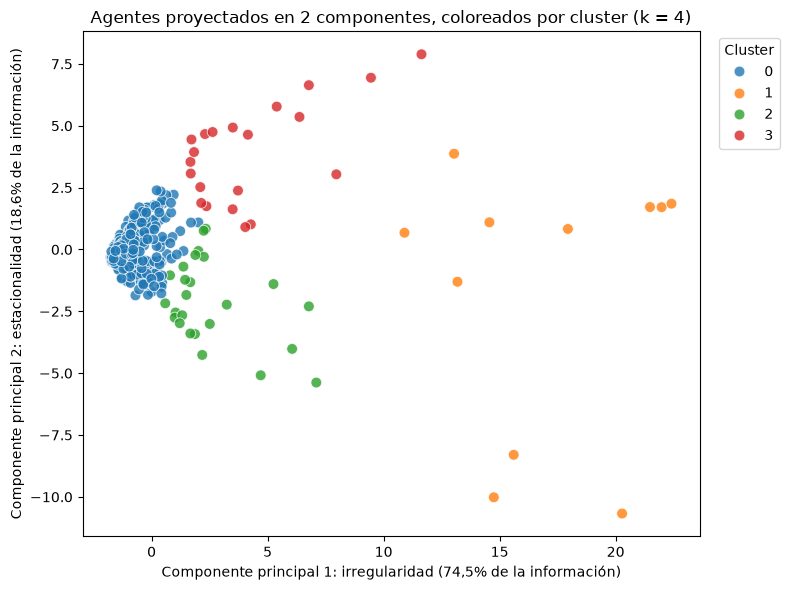

In [135]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=datos["cluster_k4"], palette="tab10", s=60, alpha=0.8)
plt.xlabel("Componente principal 1: irregularidad (74,5% de la información)")
plt.ylabel("Componente principal 2: estacionalidad (18,6% de la información)")
plt.title("Agentes proyectados en 2 componentes, coloreados por cluster (k = 4)")
plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

Azul = Agentes de demanda regular y sin estacionalidad marcada. Es el núcleo.

Naranja = se define por irregularidad, no por estacionalidad.

Rojo y verde = salen de lados opuestos del bloque azul, los dos grupos tienen estacionalidad contraria.
Casi no hay espacio vacío entre el azul, el rojo y el verde, no se forman grupos aislados.




In [136]:
kmeans = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE).fit(df_nosup)
etiquetas = pd.Series(kmeans.labels_, index=df_nosup.index, name="cluster")

print("Inercia:", round(kmeans.inertia_, 1))

originales = metricas.loc[df_nosup.index, ["demanda_media", "cv", "ind_estacional"]]

perfil = originales.groupby(etiquetas).agg(
    agentes=("demanda_media", "size"),
    demanda_media=("demanda_media", "mean"),
    demanda_mediana=("demanda_media", "median"),
    cv=("cv", "mean"),
    ind_estacional=("ind_estacional", "mean"),
).round(2)

perfil["% de agentes"] = (perfil["agentes"] / perfil["agentes"].sum() * 100).round(1)
perfil["% de la demanda"] = (originales.groupby(etiquetas)["demanda_media"].sum() / originales["demanda_media"].sum() * 100).round(1)
perfil

Inercia: 1658.4


,agentes,demanda_media,demanda_mediana,cv,ind_estacional,% de agentes,% de la demanda
cluster,,,,,,,
0,417,27769.00,2091.53,0.15,0.05,88.0,99.3
1,11,241.73,61.24,2.69,-0.86,2.3,0.0
2,25,2315.82,1011.06,0.61,-0.64,5.3,0.5
3,21,976.44,556.18,0.92,1.06,4.4,0.2


El K-Means con k = 4 (inercia 1.658) separa a los agentes en un grupo principal y tres grupos pequeños con patrones atípicos. El cluster 0 reúne al 88% de los agentes y al 99,3% de la demanda, con consumo estable y sin estacionalidad. Los clusters 1, 2 y 3, que suman el 12% de los agentes pero solo el 0,7% de la demanda, corresponden a una demanda muy irregular (cluster 1, cv 2,69), con pico de invierno (cluster 2, estacionalidad −0,64) y con pico de verano (cluster 3, estacionalidad +1,06). Hay patrones atípicos, pero se concentran en agentes de bajo volumen.

Coincidencia con categorías reales

In [137]:
tabla = pd.crosstab(etiquetas, clase[etiquetas.index], rownames=["cluster"], colnames=["tipo de agente"])
print(tabla)
print()
print((tabla.div(tabla.sum(axis=1), axis=0) * 100).round(1))

tipo de agente  Autogenerador  Distribuidor  Gran Usuario
cluster                                                  
0                           7            76           333
1                           9             0             2
2                           4             0            21
3                          11             0            10

tipo de agente  Autogenerador  Distribuidor  Gran Usuario
cluster                                                  
0                         1.7          18.3          80.0
1                        81.8           0.0          18.2
2                        16.0           0.0          84.0
3                        52.4           0.0          47.6


Los clusters obtenidos no reproducen la clasificación por tipo de agente. Los 76 Distribuidores y 333 de los 366 Grandes Usuarios quedan en el cluster 0 (demanda estable), por lo que el patrón mensual no permite distinguir entre ambas categorías. Los Autogeneradores, en cambio, se separan: 24 de los 31 se ubican en los clusters de patrón atípico, y constituyen el 82% del cluster de demanda muy irregular (cluster 1) y el 52% del cluster con pico de verano (cluster 3). Los patrones atípicos no son exclusivos de los Autogeneradores, ya que 33 Grandes Usuarios también se ubican en esos clusters, 21 de ellos con pico de invierno. En síntesis, la coincidencia con las categorías reales es baja: solo los Autogeneradores se diferencian de forma parcial.

**Inicialización**

In [138]:
filas = []
for semilla in range(10):
    km = KMeans(n_clusters=4, n_init=1, random_state=semilla).fit(df_nosup)
    tamanos = sorted(pd.Series(km.labels_).value_counts().tolist(), reverse=True)
    filas.append({"semilla": semilla, "inercia": round(km.inertia_, 1), "tamaños de cluster": tamanos})

pd.DataFrame(filas)

,semilla,inercia,tamaños de cluster
0,0,1692.2,"[428, 33, 10, 3]"
1,1,1753.2,"[338, 105, 22, 9]"
2,2,1739.3,"[337, 100, 27, 10]"
3,3,1787.1,"[438, 22, 10, 4]"
4,4,1745.4,"[312, 123, 28, 11]"
5,5,1688.9,"[428, 34, 9, 3]"
6,6,1744.1,"[338, 99, 26, 11]"
7,7,1660.2,"[420, 22, 21, 11]"
8,8,1743.8,"[337, 100, 26, 11]"
9,9,1671.2,"[409, 44, 12, 9]"


Para evaluar la estabilidad de K-Means con k = 4 se entrenó el modelo con 10 semillas distintas y un solo intento de inicialización (n_init = 1). Ninguna alcanzó la inercia de la solución final (1658,4), obtenida repitiendo 10 inicializaciones y conservando la mejor; la más cercana fue la semilla 7 (1660,2), cuyos tamaños de cluster [420, 22, 21, 11] son casi idénticos a los de la solución final [417, 25, 21, 11]. 

**MODELO DE APRENDIZAJE SUPERVISADO**

La variable objetivo del modelo supervisado es el tipo de agente (TIPO AGENTE), porque es una característica del agente como tal: cada agente del MEM tiene un único valor. En cambio, CATEGORIA DEMANDA y TIPO DEMANDA son propiedades de cada fila (cada registro mensual de demanda), por lo que un mismo agente puede aparecer con más de un valor. Como nuestro DataFrame tiene una fila por agente, necesitamos una etiqueta que sea única por agente.

In [139]:
## Verificamos que cada agente tenga un solo tipo de agente, que es la variable target

tipo_x_agente = df.groupby('AGENTE NEMO')['TIPO AGENTE'].nunique()
print(tipo_x_agente.value_counts())

TIPO AGENTE
1    557
Name: count, dtype: int64


In [140]:
## Cuántos hay de cada tipo de agente

tipo_x_agente = df.groupby('TIPO AGENTE')['AGENTE NEMO'].nunique()
print(tipo_x_agente)

TIPO AGENTE
AG     36
AR      3
DI     76
DM      1
GU    441
Name: AGENTE NEMO, dtype: int64


In [141]:
solo_ar_dm = df[df['TIPO AGENTE'].isin(['AR', 'DM'])]

una_fila_por_agente = solo_ar_dm.drop_duplicates(subset='AGENTE NEMO')

print(una_fila_por_agente[['AGENTE NEMO', 'AGENTE DESCRIPCION', 'TIPO AGENTE', 'REGION', 'TIPO DEMANDA']])

      AGENTE NEMO              AGENTE DESCRIPCION TIPO AGENTE        REGION  \
731      ALUAREUA     ALUAR SA AUTOGENERADOR REN.          AR    PATAGONICA   
733      AGRIQIDA           AGRITUR SAN LUIS S.A.          AR        CENTRO   
749      CPIEDR1Q        COOPERATIVA DE PIEDRITAS          DM  BUENOS AIRES   
17194    CEMAGIDA  AG CEMENTOS AVELLANEDA S. Luis          AR        CENTRO   

                           TIPO DEMANDA  
731                                GUMA  
733                                GUMA  
749    No Residencial (ESTACIONALIZADA)  
17194                              GUMA  


In [142]:
solo_ag = df[df['TIPO AGENTE'] == 'AG']

una_fila_por_agente_ag = solo_ag.drop_duplicates(subset='AGENTE NEMO')

print(una_fila_por_agente_ag[['AGENTE NEMO', 'AGENTE DESCRIPCION', 'REGION', 'TIPO DEMANDA']].head(15))

    AGENTE NEMO              AGENTE DESCRIPCION        REGION TIPO DEMANDA
22     APARPPNA           ALTO PARANA-PTO.PIRAY       NORESTE         GUMA
36     ARCOLPTA        ARCOR ING.LA PROVIDENCIA      NOROESTE         GUMA
38     ARCOMSXA     ARCOR MARIO SEVESO ARROYITO        CENTRO         GUMA
65     AZUCTETA       AZUCARERA JUAN M.TERAN SA      NOROESTE         GUMA
90     CAPEX-QA        CAPEX S.A. AUTOGENERADOR       COMAHUE         GUMA
161    CHEVHUQA  CHEVRON ARGENTINA - HUANTRAICO       COMAHUE         GUMA
482    IRTABAAA  Ingenio y Ref.S.Martin Tabacal      NOROESTE         GUMA
493    LEDESMYA                    LEDESMA SAAI      NOROESTE         GUMA
535    MRPLSLSA  MOLINOS AGRO AG.(Ex.Mol Rio P)       LITORAL         GUMA
540    NIDEJU1A          NIDERA SAFORCADA-Junin  BUENOS AIRES         GUMA
558    PETRELRA   YAC.ENTRE LOMAS AUTOGENERADOR       COMAHUE         GUMA
603    SEMINOSA           MOLINO JUAN SEMINO SA       LITORAL         GUMA
604    SHELDSCA       SHE

Los tipos **AG** y **AR** tienen muy pocos agentes (36 y 3). Al revisar sus nombres, ambos corresponden a empresas industriales (por ejemplo Arcor, Ledesma, Siderar, Shell, Aluar, Cementos Avellaneda), todas con TIPO DEMANDA GUMA. Por su perfil similar y para evitar clases con casi ningún ejemplo (imposibles de dividir en entrenamiento/prueba y de validar), se unieron en una única clase llamada “Autogenerador”.

El tipo **DM** tiene un único agente. Con una sola observación no se puede estratificar, ni dividir en entrenamiento y prueba, ni validar de forma cruzada, por lo que el modelo no podría aprender ni evaluarse sobre esa clase. Se excluyó del análisis supervisado.

**Gran Usuario** y **Distribuidor** son los dos tipos con más agentes y representan perfiles de consumo distintos (los distribuidores abastecen a poblaciones enteras; los grandes usuarios son consumidores individuales).Además hay que tener en cuenta que son clases **desbalanceadas**.

In [143]:
## Se identifican los agentes del periodo temporal elegido.
## Clase es la variable targuet.

tipo_por_agente = df.drop_duplicates(subset='AGENTE NEMO').set_index('AGENTE NEMO')['TIPO AGENTE']
mapa = {'GU': 'Gran Usuario', 'DI': 'Distribuidor', 'AG': 'Autogenerador', 'AR': 'Autogenerador'}
clase = tipo_por_agente.map(mapa)
print(clase[metricas.index].value_counts(dropna=False))

TIPO AGENTE
Gran Usuario     366
Distribuidor      76
Autogenerador     31
NaN                1
Name: count, dtype: int64


In [144]:
## Df para el modelo de aprendizaje supervisado.

df_sup = metricas[['log_demanda_media', 'cv', 'ind_estacional']].copy()
df_sup['clase'] = clase[df_sup.index]
df_sup = df_sup.dropna(subset=['clase'])

print(df_sup.shape)
print(df_sup['clase'].value_counts())
df_sup.head()

(473, 4)
clase
Gran Usuario     366
Distribuidor      76
Autogenerador     31
Name: count, dtype: int64


,log_demanda_media,cv,ind_estacional,clase
AGENTE NEMO,,,,
AARGTAOY,7.274995,0.147734,0.286221,Gran Usuario
ABRILHCY,7.087725,0.170492,0.146255,Gran Usuario
ACARQQ3Y,6.008318,0.225963,-0.469717,Gran Usuario
ACARSLSY,5.977395,0.154134,0.004369,Gran Usuario
ACERBR1Y,9.820301,0.324998,-0.226455,Gran Usuario


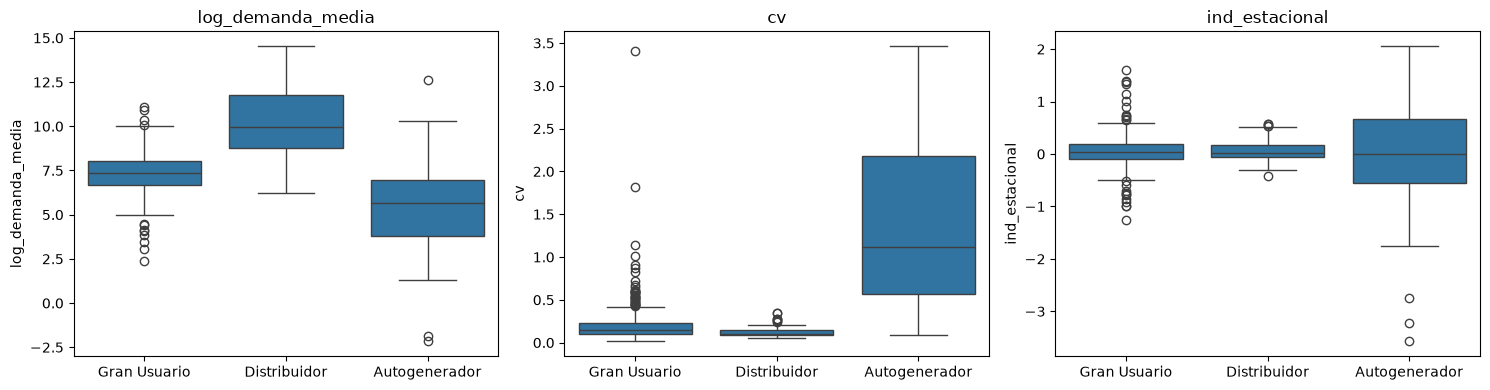

In [145]:
## Boxplots para distinguir si las features se correlacionan con las clases.

orden = ['Gran Usuario', 'Distribuidor', 'Autogenerador']
variables = ['log_demanda_media', 'cv', 'ind_estacional']

fig, ejes = plt.subplots(1, 3, figsize=(15, 4))

for eje, variable in zip(ejes, variables):
    sns.boxplot(data=df_sup, x='clase', y=variable, order=orden, ax=eje)
    eje.set_title(variable)
    eje.set_xlabel('')

plt.tight_layout()
plt.show()

Los boxplots por clase muestran que las variables seleccionadas tienen poder discriminante parcial. El nivel de demanda (log_demanda_media) separa a los Distribuidores, que tienen consumos sensiblemente mayores. El coeficiente de variación distingue a los Autogeneradores, con una demanda mucho más irregular. El índice estacional presenta medianas similares en las tres clases, por lo que su aporte discriminante parece limitado. Se observan además valores extremos en las tres variables.

In [146]:
## Separamos el df en x e y

X_sup = df_sup.drop(columns=['clase'])
y_sup = df_sup['clase']

print(X_sup.shape)
print(y_sup.shape)

(473, 3)
(473,)


In [147]:
## dividimos en entrenamiento y prueba

X_sup_train, X_sup_test, y_sup_train, y_sup_test = train_test_split(
    X_sup, y_sup, test_size=0.2, random_state=42, stratify=y_sup
)

print(X_sup_train.shape)
print(X_sup_test.shape)
print(y_sup_train.shape)
print(y_sup_test.shape)


(378, 3)
(95, 3)
(378,)
(95,)


In [148]:
## Verificamos proporción de las clases.

print(y_sup_train.value_counts())
print(y_sup_test.value_counts())

clase
Gran Usuario     292
Distribuidor      61
Autogenerador     25
Name: count, dtype: int64
clase
Gran Usuario     74
Distribuidor     15
Autogenerador     6
Name: count, dtype: int64


In [149]:
## Proponemos un modelo base: DummyClassifier
## Si bien calculamos Accuracy, no es la métrica más representativa, porque las clases están desbalanceadas.
## F1 macro porque asigna el mismo peso a cada clase, independientemente de su tamaño.

modelo_base = DummyClassifier(strategy='most_frequent')
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

acc_base = cross_val_score(modelo_base, X_sup_train, y_sup_train, cv=cv, scoring='accuracy')
f1_base = cross_val_score(modelo_base, X_sup_train, y_sup_train, cv=cv, scoring='f1_macro')

print('Accuracy promedio:', acc_base.mean().round(3), '| desvío =', acc_base.std().round(3))
print('F1 macro promedio:', f1_base.mean().round(3), '| desvío =', f1_base.std().round(3))

Accuracy promedio: 0.772 | desvío = 0.005
F1 macro promedio: 0.291 | desvío = 0.001


In [150]:
## Comparamos modelos: reg. log., arbol de dec. y random forest.

modelos = {
    'Base (Dummy)': modelo_base,
    'Regresión logística': Pipeline([
        ('escalador', RobustScaler()),
        ('clasificador', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
    ]),
    'Árbol de decisión': DecisionTreeClassifier(max_depth=4, class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42)
}

resultados = []
puntajes_por_modelo = {}

for nombre, modelo in modelos.items():
    puntajes = cross_val_score(modelo, X_sup_train, y_sup_train, cv=cv, scoring='f1_macro')
    puntajes_por_modelo[nombre] = puntajes
    resultados.append({'modelo': nombre, 'F1 macro promedio': puntajes.mean(), 'desvío': puntajes.std()})

tabla_modelos = pd.DataFrame(resultados)
print(tabla_modelos.round(3))


                modelo  F1 macro promedio  desvío
0         Base (Dummy)              0.291   0.001
1  Regresión logística              0.661   0.078
2    Árbol de decisión              0.665   0.109
3        Random Forest              0.745   0.072


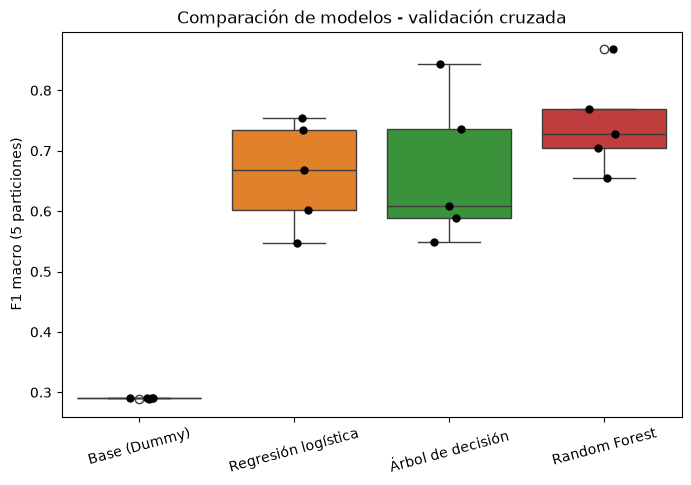

In [151]:
## Evaluar graficamente que modelo es mejor.

tabla_puntajes = pd.DataFrame(puntajes_por_modelo)

plt.figure(figsize=(8, 5))
sns.boxplot(data=tabla_puntajes)
sns.stripplot(data=tabla_puntajes, color='black', size=6)
plt.ylabel('F1 macro (5 particiones)')
plt.title('Comparación de modelos - validación cruzada')
plt.xticks(rotation=15)
plt.show()

No parece haber diferencias claras, sin embrago random forest es el más compacto y tiene un boxplot que alcanza mejor métrica.

Armamos una matriz de confusión 3X3 para ver en que clase se equivoca más en random forest.

               Gran Usuario  Distribuidor  Autogenerador
Gran Usuario            259            21             12
Distribuidor             13            48              0
Autogenerador             6             3             16


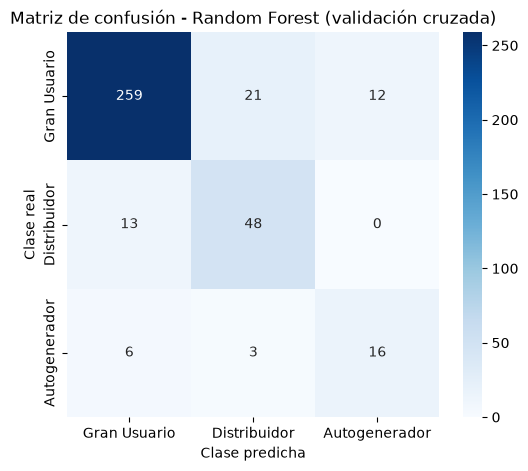

In [152]:
clases_orden = ['Gran Usuario', 'Distribuidor', 'Autogenerador']

modelo_rf = RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42)
y_pred_cv = cross_val_predict(modelo_rf, X_sup_train, y_sup_train, cv=cv)

matriz = confusion_matrix(y_sup_train, y_pred_cv, labels=clases_orden)
matriz_df = pd.DataFrame(matriz, index=clases_orden, columns=clases_orden)
print(matriz_df)

plt.figure(figsize=(6, 5))
sns.heatmap(matriz_df, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Clase predicha')
plt.ylabel('Clase real')
plt.title('Matriz de confusión - Random Forest (validación cruzada)')
plt.show()

La matriz de confusión del Random Forest (validación cruzada sobre el conjunto de entrenamiento) muestra que la clase Gran Usuario se clasifica correctamente en la mayoria de los casos, seguida de Distribuidor y Autogenerador. La mayoría de los errores corresponden a Grandes Usuarios, clasificados como autog. o distrib. También hay Distribuidores (13) y Autogeneradores (6) clasificados como Gran Usuario. La clase Autogenerador, con solo 25 agentes de entrenamiento, es la más difícil de detectar.

Ahora ajustamos los hiperparámetros del random forest, para encontrar los que mejoren las métricas.

In [153]:
## Usamos gridsearchcv, entre 100 y 300 árboles, entre 8 y ninguna profunfidad max. y un mínimo de muestra entre 1 y 5.

parametros = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 8, None],
    'min_samples_leaf': [1, 2, 5]
}

busqueda = GridSearchCV(
    RandomForestClassifier(class_weight='balanced', random_state=42),
    param_grid=parametros,
    cv=cv,
    scoring='f1_macro'
)
busqueda.fit(X_sup_train, y_sup_train)

print('Mejores parámetros:', busqueda.best_params_)
print('Mejor F1 macro (CV):', round(busqueda.best_score_, 3))
i = busqueda.best_index_
print('Desvío del mejor modelo:', round(busqueda.cv_results_['std_test_score'][i], 3))

Mejores parámetros: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 300}
Mejor F1 macro (CV): 0.753
Desvío del mejor modelo: 0.086


Mejora respecto de los que pusimos al principio, pasa de un F1 de 0,745 a 0,753.
Sin embargo la diferencia entre ella es del orden del desvío entre las particiones.

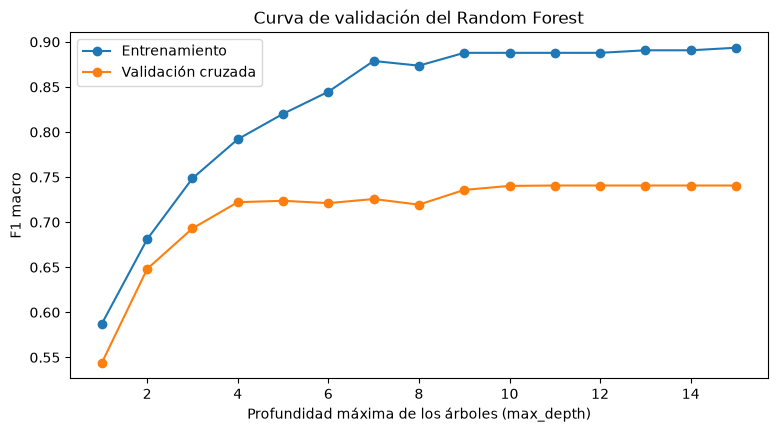

In [154]:
## Para evaluar overfitting si no usamos CV.

profundidades = range(1, 16)
f1_tr, f1_cv = [], []

for d in profundidades:
    rf = RandomForestClassifier(n_estimators=200, max_depth=d, min_samples_leaf=2,
                                class_weight='balanced', random_state=42)
    f1_cv.append(cross_val_score(rf, X_sup_train, y_sup_train, cv=cv, scoring='f1_macro').mean())
    rf.fit(X_sup_train, y_sup_train)
    f1_tr.append(f1_score(y_sup_train, rf.predict(X_sup_train), average='macro'))

plt.figure(figsize=(9, 4.5))
plt.plot(profundidades, f1_tr, 'o-', label='Entrenamiento')
plt.plot(profundidades, f1_cv, 'o-', label='Validación cruzada')
plt.xlabel('Profundidad máxima de los árboles (max_depth)')
plt.ylabel('F1 macro')
plt.title('Curva de validación del Random Forest')
plt.legend()
plt.show()

La curva de validación muestra que, al aumentar la profundidad de los árboles, el F1 de entrenamiento (sin CV) sube hasta aprox. 0,90, mientras que el de validación cruzada se estabiliza en aprox. 0,75 desde profundidad 4. Hay cierta diferencia entre ambos (overfitting).

F1 macro en test: 0.745
               precision    recall  f1-score   support

 Gran Usuario       0.92      0.82      0.87        74
 Distribuidor       0.50      0.73      0.59        15
Autogenerador       0.71      0.83      0.77         6

     accuracy                           0.81        95
    macro avg       0.71      0.80      0.75        95
 weighted avg       0.84      0.81      0.82        95

               Gran Usuario  Distribuidor  Autogenerador
Gran Usuario             61            11              2
Distribuidor              4            11              0
Autogenerador             1             0              5


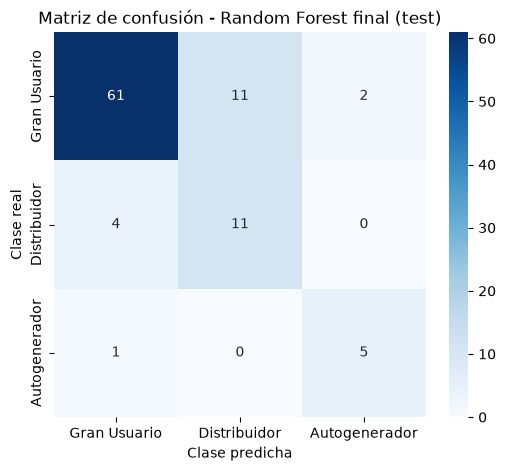

In [155]:
## Prueba con datos de testeo y evaluación de las métrica de testeo.

modelo_final = busqueda.best_estimator_
y_pred_test = modelo_final.predict(X_sup_test)

print('F1 macro en test:', round(f1_score(y_sup_test, y_pred_test, average='macro'), 3))
print(classification_report(y_sup_test, y_pred_test, labels=clases_orden))

matriz_test = confusion_matrix(y_sup_test, y_pred_test, labels=clases_orden)
matriz_test_df = pd.DataFrame(matriz_test, index=clases_orden, columns=clases_orden)
print(matriz_test_df)

plt.figure(figsize=(6, 5))
sns.heatmap(matriz_test_df, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Clase predicha')
plt.ylabel('Clase real')
plt.title('Matriz de confusión - Random Forest final (test)')
plt.show()

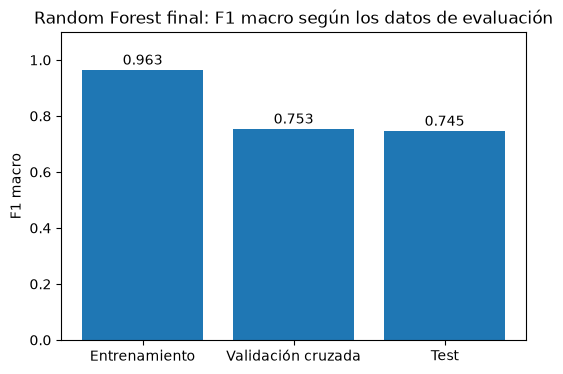

In [156]:
f1_entrenamiento = f1_score(y_sup_train, modelo_final.predict(X_sup_train), average='macro')
f1_validacion = busqueda.best_score_
f1_test = f1_score(y_sup_test, modelo_final.predict(X_sup_test), average='macro')

etapas = ['Entrenamiento', 'Validación cruzada', 'Test']
valores = [f1_entrenamiento, f1_validacion, f1_test]

plt.figure(figsize=(6, 4))
plt.bar(etapas, valores)
for i, valor in enumerate(valores):
    plt.text(i, valor + 0.02, round(valor, 3), ha='center')
plt.ylim(0, 1.1)
plt.ylabel('F1 macro')
plt.title('Random Forest final: F1 macro según los datos de evaluación')
plt.show()

El Random Forest final obtuvo un F1 macro de 0,963 en el conjunto de entrenamiento, 0,753 en validación cruzada y 0,745 en el conjunto de test. La diferencia entre entrenamiento y validación indica sobreajuste; sin embargo, el desempeño en test es prácticamente igual al de validación cruzada, lo que indica que el modelo generaliza adecuadamente a agentes no vistos durante el entrenamiento.